In [1]:
import os, glob
import numpy as np
import tensorflow as tf
import pandas as pd

I0000 00:00:1795097896.925406  104853 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795097897.033458  104853 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1795097900.787681  104853 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## Prepare dataset

In [2]:
CAPTURES = "../dataset/captures"
MAX_LEN  = 100 
N_CH     = 6 
# Binary problem: one sigmoid output. 0 = extension, 1 = flexion.
classes = ["label_WRIST_EXTENSION", "label_WRIST_FLEXION"]
class_to_id = {c: i for i, c in enumerate(classes)}

for cls in classes:
    assert glob.glob(os.path.join(CAPTURES, cls, "*.csv")), f"no csv for {cls}"

lengths = []
"""
Load and preprocess the gesture recordings to create the dataset for training the MLP.

For each gesture class, the function:
1. Loads the accelerometer and gyroscope measurements from CSV files.
2. Creates a fixed-size sequence using zero-padding or truncation.
3. Flattens the 2D sensor matrix into a 1D feature vector.
4. Assigns a numerical label to identify the gesture.

Finally, X contains the input features and y contains the corresponding gesture labels.
"""

X, y = [], []
for cls in classes:
    for path in glob.glob(os.path.join(CAPTURES, cls, "*.csv")):
        rows = np.loadtxt(path, delimiter=",", skiprows=1, usecols=range(4, 10))
        seq = np.zeros((MAX_LEN, N_CH), dtype=np.float32)   
        n = min(rows.shape[0], MAX_LEN)
        seq[:n] = rows[:n]
        X.append(seq.flatten())          
        y.append(class_to_id[cls])

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.float32)   # 0.0 / 1.0
print("X", X.shape, "classes", classes)  

X (60, 600) classes ['label_WRIST_EXTENSION', 'label_WRIST_FLEXION']


## Analyze dataset

In [3]:
CHANNELS = ["ax", "ay", "az", "gx", "gy", "gz"]


def class_balance(y, classes):
    """Print the number and share of samples per gesture class."""
    labels, counts = np.unique(y, return_counts=True)
    for lab, cnt in zip(labels, counts):
        print(f"  {classes[int(lab)]:24s} {int(cnt):3d}  ({cnt / len(y):.0%})")
    print(f"  total {len(y)} samples")


def sensor_stats(X, channels=CHANNELS):
    """Per-channel min/max/mean/std over the (samples, MAX_LEN, N_CH) tensor."""
    X3 = X.reshape(len(X), MAX_LEN, N_CH)
    for c, name in enumerate(channels):
        ch = X3[:, :, c]
        print(f"  {name:3s} min={ch.min():8.2f} max={ch.max():8.2f} "
              f"mean={ch.mean():8.2f} std={ch.std():8.2f}")
    print(f"  any NaN: {np.isnan(X).any()}  any Inf: {np.isinf(X).any()}")


print(f"X {X.shape}  y {y.shape}")
print("class balance:")
class_balance(y, classes)
print("\nper-channel stats (all samples):")
sensor_stats(X)

X (60, 600)  y (60,)
class balance:
  label_WRIST_EXTENSION     30  (50%)
  label_WRIST_FLEXION       30  (50%)
  total 60 samples

per-channel stats (all samples):
  ax  min=   -1.18 max=    1.02 mean=   -0.00 std=    0.81
  ay  min=   -0.21 max=    0.48 mean=    0.18 std=    0.08
  az  min=   -1.29 max=    0.67 mean=   -0.41 std=    0.43
  gx  min=  -76.06 max=  118.25 mean=   -3.07 std=   13.26
  gy  min= -221.25 max=  197.38 mean=    5.95 std=   51.84
  gz  min=  -50.47 max=   58.85 mean=   -6.97 std=    8.29
  any NaN: False  any Inf: False


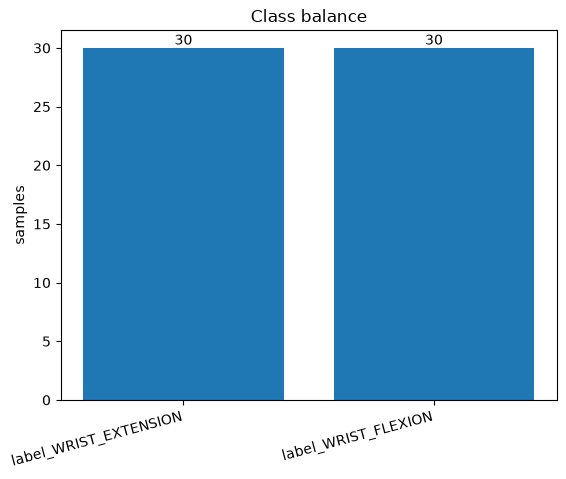

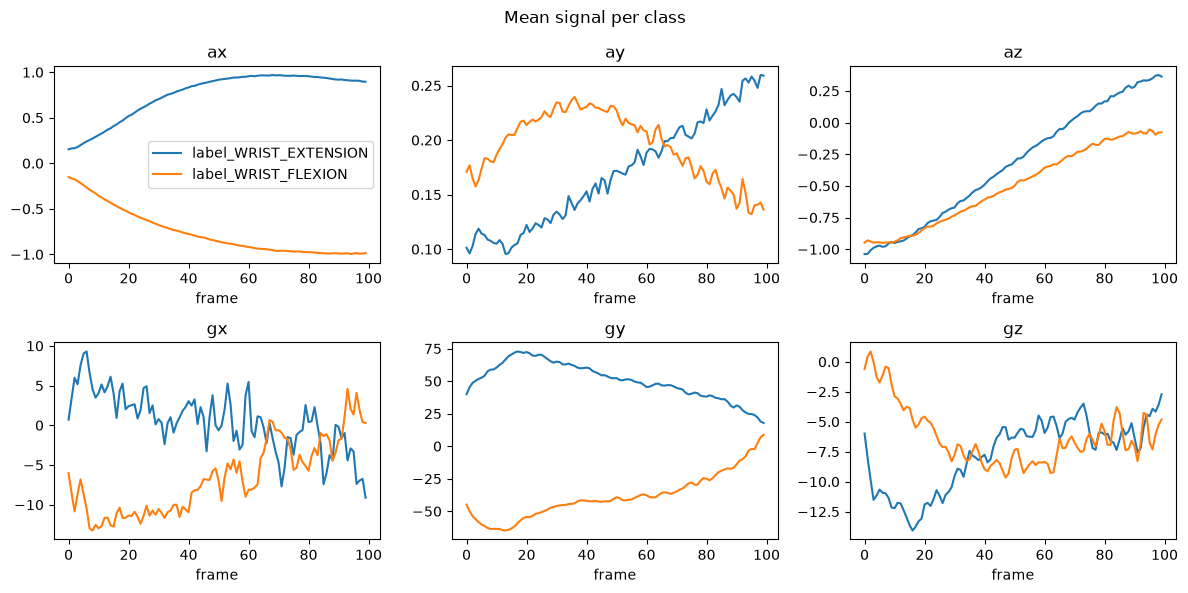

In [4]:
import matplotlib.pyplot as plt

X3 = X.reshape(len(X), MAX_LEN, N_CH)


def plot_class_balance(y, classes):
    labels, counts = np.unique(y, return_counts=True)
    bars = plt.bar([classes[int(l)] for l in labels], counts)
    plt.ylabel("samples")
    plt.title("Class balance")
    plt.xticks(rotation=15, ha="right")
    for b, c in zip(bars, counts):
        plt.text(b.get_x() + b.get_width() / 2, c, str(c), ha="center", va="bottom")

def plot_mean_signal(X3, y, classes, channels=CHANNELS):
    fig, axes = plt.subplots(2, 3, figsize=(12, 6))
    for c, (name, ax) in enumerate(zip(channels, axes.flat)):
        for k in np.unique(y):
            ax.plot(X3[y == k][:, :, c].mean(axis=0), label=classes[int(k)])
        ax.set_title(name)
        ax.set_xlabel("frame")
    axes[0, 0].legend()
    fig.suptitle("Mean signal per class")
    fig.tight_layout()


plot_class_balance(y, classes)
plot_mean_signal(X3, y, classes)

## Hyperparameter tuning 

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import keras_tuner as kt
import numpy as np
import tensorflow as tf

# 1. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)

# 2. Normalize data
scaler = StandardScaler().fit(X_train)

X_train = scaler.transform(X_train).astype(np.float32)
X_val = scaler.transform(X_val).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)


# 3. Build neural network
def build_model(hp):
    model = tf.keras.Sequential()

    model.add(tf.keras.layers.Input(shape=(600,)))

    for i in range(hp.Int("num_layers", 1, 3)):
        model.add(tf.keras.layers.Dense(
            units=hp.Int(
                f"units_{i}",
                min_value=16,
                max_value=128,
                step=16
            ),
            activation="relu"
        ))

    model.add(tf.keras.layers.Dense(len(classes), activation="softmax"))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=hp.Choice("lr", [1e-2, 1e-3, 1e-4])
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


# 4. Configure Keras Tuner
tuner = kt.RandomSearch(
    build_model,
    objective="val_accuracy",
    max_trials=10,
    directory="results",
    project_name="gesture_recognition_softmax"
)

# 5. Search for the best architecture
tuner.search(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30
)

# 6. Retrieve best model
best_model = tuner.get_best_models(num_models=1)[0]

# 7. Retrieve best hyperparameters
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

print("Best hyperparameters:", best_hp.values)

# 8. Evaluate using test dataset
test_loss, test_accuracy = best_model.evaluate(X_test, y_test)

print("Test accuracy:", test_accuracy)



Trial 10 Complete [00h 00m 09s]
val_accuracy: 1.0

Best val_accuracy So Far: 1.0
Total elapsed time: 00h 01m 42s


/home/arans/Uni/omniflux/Train/.venv/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(store)


Best hyperparameters: {'num_layers': 2, 'units_0': 32, 'lr': 0.001, 'units_1': 16}


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 559ms/step - accuracy: 1.0000 - loss: 0.0255

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 601ms/step - accuracy: 1.0000 - loss: 0.0255


Test accuracy: 1.0


In [6]:
model = tuner.hypermodel.build(best_hp)

model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30
)

Epoch 1/30


1/2 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.3438 - loss: 0.8119

2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 466ms/step - accuracy: 0.4474 - loss: 0.7421 - val_accuracy: 0.8000 - val_loss: 0.5101


Epoch 2/30


1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 1.0000 - loss: 0.1718

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step - accuracy: 1.0000 - loss: 0.1596 - val_accuracy: 0.8000 - val_loss: 0.3535


... (80 outputs left out)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step - accuracy: 1.0000 - loss: 1.2766e-04 - val_accuracy: 1.0000 - val_loss: 0.0393


Epoch 30/30


1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 1.0000 - loss: 1.4097e-04

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step - accuracy: 1.0000 - loss: 1.2326e-04 - val_accuracy: 1.0000 - val_loss: 0.0391


## Test trained network

In [7]:
from sklearn.metrics import classification_report, confusion_matrix

loss, acc = model.evaluate(X_test, y_test, verbose=0)
y_pred = model.predict(X_test, verbose=0).argmax(axis=1)

print(f"test loss {loss:.4f}  accuracy {acc:.4f}  ({len(y_test)} samples)")
print(classification_report(y_test.astype(int), y_pred, target_names=classes, digits=3, zero_division=0))

cm = confusion_matrix(y_test.astype(int), y_pred, labels=[0, 1])
for i, c in enumerate(classes):
    print(f"{c:28s} acc={cm[i, i] / max(cm[i].sum(), 1):.2f}  n={cm[i].sum()}")

test loss 0.0005  accuracy 1.0000  (12 samples)
                       precision    recall  f1-score   support

label_WRIST_EXTENSION      1.000     1.000     1.000         6
  label_WRIST_FLEXION      1.000     1.000     1.000         6

             accuracy                          1.000        12
            macro avg      1.000     1.000     1.000        12
         weighted avg      1.000     1.000     1.000        12

label_WRIST_EXTENSION        acc=1.00  n=6
label_WRIST_FLEXION          acc=1.00  n=6


## Architecture grid search (size vs accuracy)

The first Dense layer holds 76.8k of the 86.2k parameters, so input width dominates the size. Grid over temporal average-pooling (`stride` frames -> one) and hidden layer sizes; every model gets the same epochs and the same split. `int8_kb` assumes 1 byte per parameter (the real TFLite size is measured in the next cell).

The 2-class test set is small (a few dozen samples), so treat differences under ~5 points as noise.

In [8]:
GRID_STRIDES = [1, 2, 4]                      # average this many frames together
GRID_HIDDEN  = [(128, 64), (64, 32), (32, 16), (16,)]
GRID_EPOCHS  = 80


def fold(Xs, stride):
    """Average-pool groups of `stride` frames; MAX_LEN is divisible by 1/2/4."""
    if stride == 1:
        return Xs
    return Xs.reshape(-1, MAX_LEN // stride, stride, N_CH).mean(2).reshape(len(Xs), -1)


rows, models, splits = [], {}, {}
for stride in GRID_STRIDES:
    Xtr, Xte = fold(X_train, stride), fold(X_test, stride)
    for hidden in GRID_HIDDEN:
        name = "x".join(map(str, hidden))
        m = tf.keras.Sequential(
            [tf.keras.layers.Input((Xtr.shape[1],))]
            + [tf.keras.layers.Dense(h, activation="relu") for h in hidden]
            + [tf.keras.layers.Dense(len(classes), activation="softmax")])
        m.compile(optimizer="adam", loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
        m.fit(Xtr, y_train, batch_size=32, epochs=GRID_EPOCHS, verbose=0)
        acc = m.evaluate(Xte, y_test, verbose=0)[1]
        models[(stride, name)], splits[(stride, name)] = m, (Xtr, Xte)
        rows.append(dict(stride=stride, hidden=name, params=m.count_params(),
                         int8_kb=m.count_params() / 1024, test_acc=round(acc, 4)))

grid = pd.DataFrame(rows).sort_values("params").reset_index(drop=True)
print(grid.to_string(index=False, float_format="{:.3f}".format))

# smallest model within 2 points of the best accuracy on this grid
best_acc = grid.test_acc.max()
pick = grid[grid.test_acc >= best_acc - 0.02].iloc[0]
best_model = models[(pick.stride, pick.hidden)]
best_X_train, best_X_test = splits[(pick.stride, pick.hidden)]
best_model.save("model_best.keras")
print(f"\npicked stride={pick.stride} hidden={pick.hidden}: "
      f"~{pick['int8_kb']:.1f}KB int8, test acc {pick.test_acc:.4f} "
      f"(best on grid {best_acc:.4f})")

 stride hidden  params  int8_kb  test_acc
      4     16    2450    2.393     1.000
      2     16    4850    4.736     1.000
      4  32x16    5394    5.268     1.000
      1     16    9650    9.424     1.000
      2  32x16   10194    9.955     1.000
      4  64x32   11810   11.533     1.000
      1  32x16   19794   19.330     1.000
      2  64x32   21410   20.908     1.000
      4 128x64   27714   27.064     1.000
      1  64x32   40610   39.658     1.000
      2 128x64   46914   45.814     1.000
      1 128x64   85314   83.314     1.000

picked stride=4 hidden=16: ~2.4KB int8, test acc 1.0000 (best on grid 1.0000)


## TensorFlow Lite conversion (ESP32)

Float32 TFLite for reference, and full int8 quantization (weights + activations) which is what an ESP32 / TFLite Micro should run. The grid winner is converted with its own (pooled) representative data.

The scaler lives outside the model, so its parameters are saved separately for the firmware.

In [9]:
def to_tflite(src, int8, rep):
    conv = tf.lite.TFLiteConverter.from_keras_model(src)
    if int8:
        conv.optimizations = [tf.lite.Optimize.DEFAULT]
        conv.representative_dataset = lambda: ([x[None]] for x in rep)
        conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
        conv.inference_input_type = tf.int8
        conv.inference_output_type = tf.int8
    return conv.convert()


def tflite_accuracy(blob, X, y):
    it = tf.lite.Interpreter(model_content=blob)
    it.allocate_tensors()
    inp, out = it.get_input_details()[0], it.get_output_details()[0]
    hits = 0
    for x, label in zip(X, y):
        if inp["dtype"] == np.int8:                      # quantize the input like the MCU will
            s, z = inp["quantization"]
            x = np.clip(np.round(x / s + z), -128, 127).astype(np.int8)
        it.set_tensor(inp["index"], x[None].astype(inp["dtype"]))
        it.invoke()
        probs = it.get_tensor(out["index"])[0].astype(np.float32)
        if out["dtype"] == np.int8:                      # dequantize softmax outputs
            s, z = out["quantization"]
            probs = (probs - z) * s
        hits += int(np.argmax(probs) == int(label))
    return hits / len(y)


exports = {
    "model_float32.tflite": (to_tflite(model, False, X_train), X_test),
    "model_int8.tflite": (to_tflite(model, True, X_train), X_test),
    "model_best_int8.tflite": (to_tflite(best_model, True, best_X_train), best_X_test),
}
for name, (blob, Xte) in exports.items():
    open(name, "wb").write(blob)
    print(f"{name:26s} {len(blob) / 1024:6.1f}KB  test acc {tflite_accuracy(blob, Xte, y_test):.4f}")

# firmware must normalise raw sensor rows with the same scaler before inference
np.savez("scaler.npz", mean=scaler.mean_, scale=scaler.scale_)

INFO:tensorflow:Assets written to: /tmp/tmpc5pkl0s6/assets


INFO:tensorflow:Assets written to: /tmp/tmpc5pkl0s6/assets


Saved artifact at '/tmp/tmpc5pkl0s6'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 600), dtype=tf.float32, name='keras_tensor_7')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  132749352006864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132749352008976: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132749352007632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132749352005904: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132749352009168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132749352009360: TensorSpec(shape=(), dtype=tf.resource, name=None)


W0000 00:00:1795098143.977664  104853 tf_tfl_flatbuffer_helpers.cc:425] Ignored output_format.
W0000 00:00:1795098143.977693  104853 tf_tfl_flatbuffer_helpers.cc:428] Ignored drop_control_dependency.
I0000 00:00:1795098143.978313  104853 reader.cc:83] Reading SavedModel from: /tmp/tmpc5pkl0s6
I0000 00:00:1795098143.979349  104853 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1795098143.979368  104853 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpc5pkl0s6
I0000 00:00:1795098143.988771  104853 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
I0000 00:00:1795098143.990493  104853 loader.cc:237] Restoring SavedModel bundle.
I0000 00:00:1795098144.051132  104853 loader.cc:221] Running initialization op on SavedModel bundle at path: /tmp/tmpc5pkl0s6
I0000 00:00:1795098144.071297  104853 loader.cc:484] SavedModel load for tags { serve }; Status: success: OK. Took 93005 microseconds.
I0000 00:00:1795098144.096286  104853

INFO:tensorflow:Assets written to: /tmp/tmplrmpm9z3/assets


INFO:tensorflow:Assets written to: /tmp/tmplrmpm9z3/assets


... (5 outputs left out)

Saved artifact at '/tmp/tmpra9nqnnc'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 150), dtype=tf.float32, name='keras_tensor_56')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  132748986155088: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132748986155856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132748452512976: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132748452519888: TensorSpec(shape=(), dtype=tf.resource, name=None)


/home/arans/Uni/omniflux/Train/.venv/lib/python3.12/site-packages/tensorflow/lite/python/convert.py:960: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


model_float32.tflite         79.5KB  test acc 1.0000
model_int8.tflite            23.1KB  test acc 1.0000
model_best_int8.tflite        4.9KB  test acc 1.0000


W0000 00:00:1795098145.853086  104853 tf_tfl_flatbuffer_helpers.cc:425] Ignored output_format.
W0000 00:00:1795098145.853120  104853 tf_tfl_flatbuffer_helpers.cc:428] Ignored drop_control_dependency.
I0000 00:00:1795098145.853567  104853 reader.cc:83] Reading SavedModel from: /tmp/tmpra9nqnnc
I0000 00:00:1795098145.854586  104853 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1795098145.854606  104853 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpra9nqnnc
I0000 00:00:1795098145.861642  104853 loader.cc:237] Restoring SavedModel bundle.
I0000 00:00:1795098145.906219  104853 loader.cc:221] Running initialization op on SavedModel bundle at path: /tmp/tmpra9nqnnc
I0000 00:00:1795098145.922100  104853 loader.cc:484] SavedModel load for tags { serve }; Status: success: OK. Took 68549 microseconds.
fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8
W0000 00:00:1795098146.079364  104853 flatbuffer_export.cc:

## Deployed grid-search model vs original tuner model

Both models use a 2-neuron softmax head. They reach 100% on the 12-window test split; on all 60 windows the grid model misses one. The deployed grid-search winner is about 4.7x smaller (4.9 KB vs 23.1 KB). The plots show accuracy and size, test-set confusion matrices, and per-window predicted probabilities.

               model  test accuracy  all-window accuracy  int8 size (KB)
original tuner model          1.000                1.000          23.133
  grid-search winner          1.000                0.983           4.898


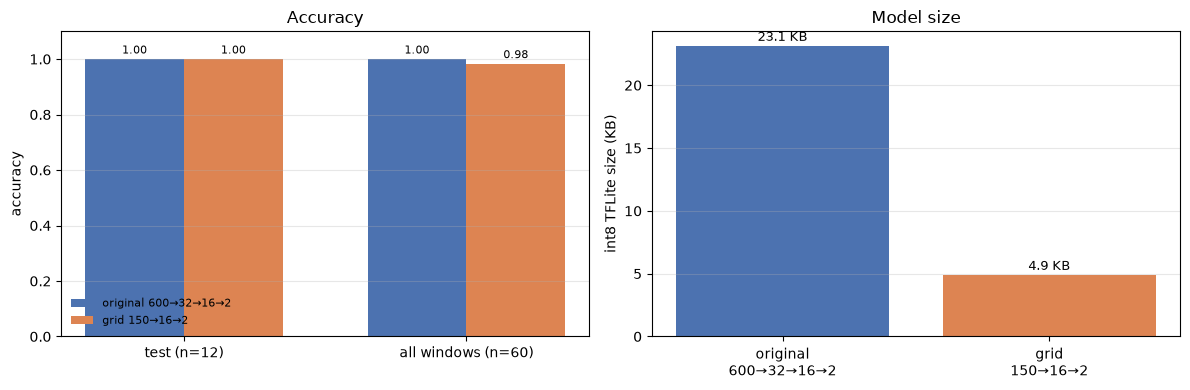

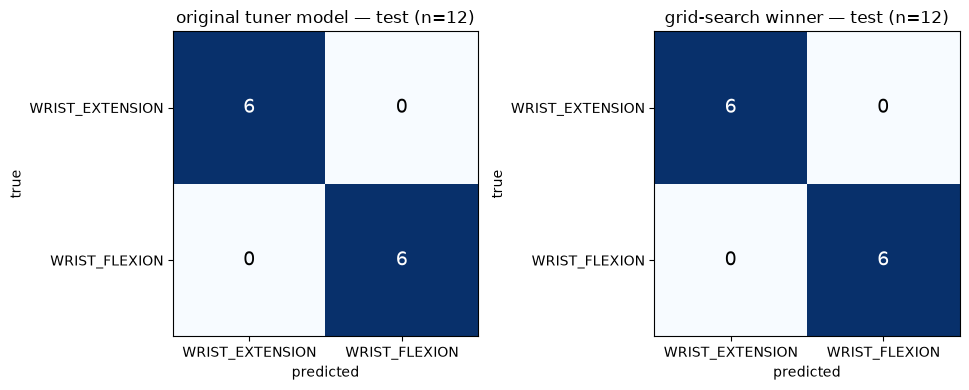

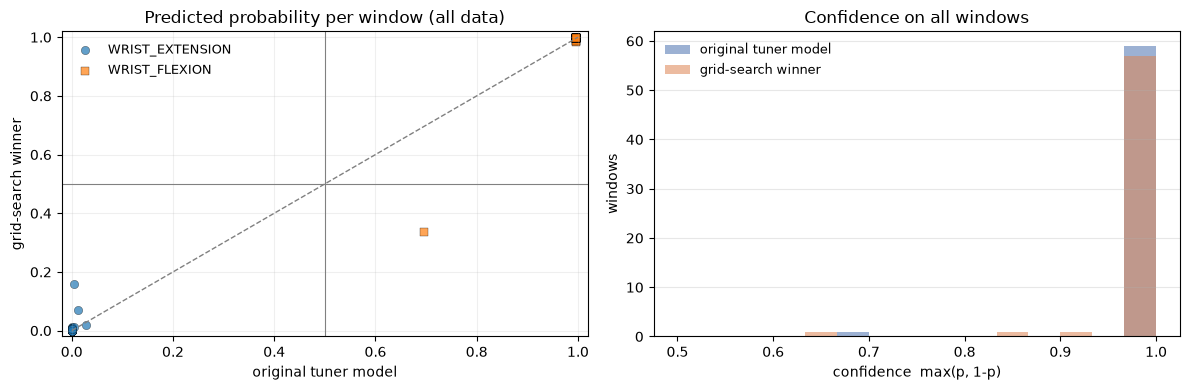

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Deployed model = grid-search winner (stride-4 pooling).
# Original   = tuner-selected model (no pooling).
MODELS = {
    "original tuner model": ("model_int8.tflite", 1, "#4c72b0"),
    "grid-search winner": ("model_best_int8.tflite", 4, "#dd8452"),
}
SHORT = {"original tuner model": "original\n600→32→16→2",
         "grid-search winner": "grid\n150→16→2"}


def tflite_probs(path, Xs, stride):
    """Run a full-int8 TFLite model on scaled windows, pooling frames if needed."""
    Xs = fold(Xs, stride) if stride > 1 else Xs
    it = tf.lite.Interpreter(model_path=path)
    it.allocate_tensors()
    inp, out = it.get_input_details()[0], it.get_output_details()[0]
    probs = []
    for x in Xs:
        s, z = inp["quantization"]
        xq = np.clip(np.round(x / s + z), -128, 127).astype(np.int8)
        it.set_tensor(inp["index"], xq[None])
        it.invoke()
        p = it.get_tensor(out["index"])[0].astype(np.float32)
        s, z = out["quantization"]
        probs.append(((p - z) * s)[1])   # P(flexion)
    return np.array(probs)


X_all = scaler.transform(X).astype(np.float32)
results = {}
for name, (path, stride, color) in MODELS.items():
    results[name] = dict(
        test=tflite_probs(path, X_test, stride),
        all=tflite_probs(path, X_all, stride),
        kb=os.path.getsize(path) / 1024,
        color=color,
    )


def accuracy(p, y_true):
    return float(((p > 0.5).astype(int) == y_true).mean())


labels = [c.replace("label_", "") for c in classes]
summary = pd.DataFrame([
    {
        "model": name,
        "test accuracy": accuracy(r["test"], y_test),
        "all-window accuracy": accuracy(r["all"], y),
        "int8 size (KB)": r["kb"],
    }
    for name, r in results.items()
])
print(summary.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

# --- accuracy and size -------------------------------------------------
names = list(results)
x = np.arange(2)
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for offset, name in zip((-width / 2, width / 2), names):
    r = results[name]
    vals = [accuracy(r["test"], y_test), accuracy(r["all"], y)]
    bars = axes[0].bar(x + offset, vals, width,
                       label=SHORT[name].replace("\n", " "), color=r["color"])
    for bar, v in zip(bars, vals):
        axes[0].text(bar.get_x() + bar.get_width() / 2, v + .02,
                     f"{v:.2f}", ha="center", fontsize=8)
axes[0].set_xticks(x, [f"test (n={len(y_test)})", f"all windows (n={len(y)})"])
axes[0].set_ylim(0, 1.1)
axes[0].set_ylabel("accuracy")
axes[0].set_title("Accuracy")
axes[0].legend(frameon=False, fontsize=8)
axes[0].grid(axis="y", alpha=.3)

sizes = [results[n]["kb"] for n in names]
bars = axes[1].bar([SHORT[n] for n in names], sizes,
                   color=[results[n]["color"] for n in names])
for bar, v in zip(bars, sizes):
    axes[1].text(bar.get_x() + bar.get_width() / 2, v + .4,
                 f"{v:.1f} KB", ha="center", fontsize=9)
axes[1].set_ylabel("int8 TFLite size (KB)")
axes[1].set_title("Model size")
axes[1].grid(axis="y", alpha=.3)
plt.tight_layout()
plt.show()

# --- test-set confusion matrices --------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, names):
    cm = confusion_matrix(y_test, (results[name]["test"] > 0.5).astype(int),
                          labels=[0, 1])
    ax.imshow(cm, cmap="Blues", vmin=0)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black",
                    fontsize=14)
    ax.set_xticks([0, 1], labels)
    ax.set_yticks([0, 1], labels)
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.set_title(f"{name} — test (n={len(y_test)})")
plt.tight_layout()
plt.show()

# --- probability behaviour on all windows -----------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
r0, r1 = results[names[0]], results[names[1]]
for cls, label, marker in [(0, labels[0], "o"), (1, labels[1], "s")]:
    axes[0].scatter(r0["all"][y == cls], r1["all"][y == cls], marker=marker,
                    alpha=.7, label=label, edgecolor="k", linewidth=.3)
axes[0].plot([0, 1], [0, 1], "--", color="gray", lw=1)
axes[0].axvline(.5, color="gray", lw=.8)
axes[0].axhline(.5, color="gray", lw=.8)
axes[0].set_xlim(-.02, 1.02)
axes[0].set_ylim(-.02, 1.02)
axes[0].set_xlabel(names[0])
axes[0].set_ylabel(names[1])
axes[0].set_title("Predicted probability per window (all data)")
axes[0].legend(frameon=False, fontsize=9)
axes[0].grid(alpha=.2)

for name in names:
    conf = np.maximum(results[name]["all"], 1 - results[name]["all"])
    axes[1].hist(conf, bins=15, range=(.5, 1), alpha=.55,
                 label=name, color=results[name]["color"])
axes[1].set_xlabel("confidence  max(p, 1-p)")
axes[1].set_ylabel("windows")
axes[1].set_title("Confidence on all windows")
axes[1].legend(frameon=False, fontsize=9)
axes[1].grid(axis="y", alpha=.3)
plt.tight_layout()
plt.show()
